In [ ]:
import pandas as pd
import sqlite3

# 1. Read the 3 CSV files using Pandas
orders = pd.read_csv('/content/drive/MyDrive/project dataset/SQL_Pythondataset/olist_orders_dataset.csv')
customers = pd.read_csv('/content/drive/MyDrive/project dataset/SQL_Pythondataset/olist_customers_dataset.csv')
items = pd.read_csv('/content/drive/MyDrive/project dataset/SQL_Pythondataset/olist_order_items_dataset.csv')

# 2. Create a local SQLite database file named 'ecommerce.db'
conn = sqlite3.connect('ecommerce.db')

# 3. Save the 3 tables inside this database
orders.to_sql('orders', conn, if_exists='replace', index=False)
customers.to_sql('customers', conn, if_exists='replace', index=False)
items.to_sql('order_items', conn, if_exists='replace', index=False)

print("Success! All 3 tables are loaded into ecommerce.db")

Success! All 3 tables are loaded into ecommerce.db


In [ ]:
# Helper function so you can run SQL queries cleanly anytime
def run_sql(query):
    return pd.read_sql_query(query, conn)

# Query 1: Preview the first 5 rows of the orders table
run_sql("SELECT * FROM orders LIMIT 5;")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
# Query 2: Check total rows and unique customers
run_sql("""
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT customer_id) AS total_order_customer_ids,
    COUNT(DISTINCT customer_unique_id) AS actual_unique_people
FROM customers;
""")

,total_rows,total_order_customer_ids,actual_unique_people
0,99441,99441,96096


In [ ]:
# Check the breakdown of order statuses (delivered vs canceled vs shipped, etc.)
run_sql("""
SELECT
    order_status,
    COUNT(*) AS total_orders
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;
""")

,order_status,total_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [ ]:
# Join the 3 tables, clean missing values, and save as a new SQL table 'clean_orders'
clean_query = """
SELECT
    o.order_id,
    c.customer_unique_id,
    c.customer_city,
    c.customer_state,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    ROUND(SUM(oi.price), 2) AS product_revenue,
    ROUND(SUM(oi.freight_value), 2) AS shipping_cost,
    ROUND(SUM(oi.price + oi.freight_value), 2) AS total_order_value,
    COUNT(oi.order_item_id) AS total_items
FROM orders o
INNER JOIN customers c
    ON o.customer_id = c.customer_id
INNER JOIN order_items oi
    ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY
    o.order_id,
    c.customer_unique_id,
    c.customer_city,
    c.customer_state,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date;
"""

# Execute the query and save the clean result back into ecommerce.db as 'clean_orders'
clean_df = run_sql(clean_query)
clean_df.to_sql('clean_orders', conn, if_exists='replace', index=False)

print(f"Done! Created 'clean_orders' with {len(clean_df):,} clean delivered orders.")
clean_df.head()

Done! Created 'clean_orders' with 96,470 clean delivered orders.


,order_id,customer_unique_id,customer_city,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,product_revenue,shipping_cost,total_order_value,total_items
0,00010242fe8c5a6d1ba2dd792cb16214,871766c5855e863f6eccc05f988b23cb,campos dos goytacazes,RJ,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29 00:00:00,58.90,13.29,72.19,1
1,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,santa fe do sul,SP,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15 00:00:00,239.90,19.93,259.83,1
2,000229ec398224ef6ca0657da4fc703e,3818d81c6709e39d06b2738a8d3a2474,para de minas,MG,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05 00:00:00,199.00,17.87,216.87,1
3,00024acbcdf0a6daa1e931b038114c75,af861d436cfc08b2c2ddefd0ba074622,atibaia,SP,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20 00:00:00,12.99,12.79,25.78,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,64b576fb70d441e8f1b2d7d446e483c5,varzea paulista,SP,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17 00:00:00,199.90,18.14,218.04,1


In [ ]:
# Query 1: Executive KPI Summary
run_sql("""
SELECT
    COUNT(DISTINCT order_id) AS total_delivered_orders,
    COUNT(DISTINCT customer_unique_id) AS total_unique_customers,
    ROUND(SUM(total_order_value), 2) AS total_gross_revenue,
    ROUND(AVG(total_order_value), 2) AS average_order_value_AOV
FROM clean_orders;
""")

,total_delivered_orders,total_unique_customers,total_gross_revenue,average_order_value_AOV
0,96470,93350,15418394.83,159.83


In [ ]:
# Query 2: Monthly Sales & Order Trend
monthly_sales = run_sql("""
SELECT
    SUBSTR(order_purchase_timestamp, 1, 7) AS order_month,
    COUNT(order_id) AS total_orders,
    ROUND(SUM(total_order_value), 2) AS monthly_revenue,
    ROUND(AVG(total_order_value), 2) AS avg_order_value
FROM clean_orders
GROUP BY order_month
ORDER BY order_month;
""")

monthly_sales

,order_month,total_orders,monthly_revenue,avg_order_value
0,2016-09,1,143.46,143.46
1,2016-10,265,46490.66,175.44
2,2016-12,1,19.62,19.62
3,2017-01,750,127482.37,169.98
4,2017-02,1653,271239.32,164.09
5,2017-03,2546,414330.95,162.74
6,2017-04,2303,390812.40,169.70
7,2017-05,3545,566657.40,159.85
8,2017-06,3135,490050.37,156.32
9,2017-07,3872,566299.08,146.25


In [ ]:
# Query 3: One-Time vs. Repeat Buyers
run_sql("""
WITH customer_orders AS (
    SELECT
        customer_unique_id,
        COUNT(order_id) AS order_count,
        SUM(total_order_value) AS total_spent
    FROM clean_orders
    GROUP BY customer_unique_id
)
SELECT
    CASE
        WHEN order_count = 1 THEN '1. One-Time Buyer'
        WHEN order_count = 2 THEN '2. Repeat Buyer (2 Orders)'
        ELSE '3. Loyal Buyer (3+ Orders)'
    END AS customer_type,
    COUNT(customer_unique_id) AS customer_count,
    ROUND(100.0 * COUNT(customer_unique_id) / (SELECT COUNT(*) FROM customer_orders), 2) AS pct_of_customers,
    ROUND(SUM(total_spent), 2) AS total_revenue,
    ROUND(100.0 * SUM(total_spent) / (SELECT SUM(total_spent) FROM customer_orders), 2) AS pct_of_revenue
FROM customer_orders
GROUP BY customer_type
ORDER BY customer_type;
""")

,customer_type,customer_count,pct_of_customers,total_revenue,pct_of_revenue
0,1. One-Time Buyer,90549,97.00,14554207.37,94.40
1,2. Repeat Buyer (2 Orders),2573,2.76,748811.57,4.86
2,3. Loyal Buyer (3+ Orders),228,0.24,115375.89,0.75


In [ ]:
# Query 4: Top 10 States by Revenue & Average Delivery Days
run_sql("""
SELECT
    customer_state,
    COUNT(order_id) AS total_orders,
    ROUND(SUM(total_order_value), 2) AS total_revenue,
    ROUND(AVG(JULIANDAY(order_delivered_customer_date) - JULIANDAY(order_purchase_timestamp)), 1) AS avg_delivery_days
FROM clean_orders
GROUP BY customer_state
ORDER BY total_revenue DESC
LIMIT 10;
""")

,customer_state,total_orders,total_revenue,avg_delivery_days
0,SP,40494,5768518.23,8.8
1,RJ,12350,2055401.57,15.3
2,MG,11354,1818891.67,12.0
3,RS,5344,861278.79,15.3
4,PR,4923,781708.80,12.0
5,SC,3546,595127.78,15.0
6,BA,3256,591137.81,19.3
7,DF,2080,346123.35,13.0
8,GO,1957,334212.35,15.6
9,ES,1995,317657.93,15.8


In [ ]:
# Query 1: Calculate RFM metrics, score with NTILE(4), and assign business segments
rfm_query = """
WITH dataset_end AS (
    SELECT MAX(order_purchase_timestamp) AS max_date
    FROM clean_orders
),
customer_metrics AS (
    SELECT
        c.customer_unique_id,
        CAST(JULIANDAY((SELECT max_date FROM dataset_end)) - JULIANDAY(MAX(c.order_purchase_timestamp)) AS INTEGER) AS recency_days,
        COUNT(DISTINCT c.order_id) AS frequency,
        ROUND(SUM(c.total_order_value), 2) AS monetary
    FROM clean_orders c
    GROUP BY c.customer_unique_id
),
rfm_scores AS (
    SELECT
        customer_unique_id,
        recency_days,
        frequency,
        monetary,
        -- Recency: fewer days since last order = higher score (4 is most recent)
        NTILE(4) OVER (ORDER BY recency_days DESC) AS r_score,
        -- Frequency: 1 order vs repeat orders
        CASE
            WHEN frequency >= 3 THEN 4
            WHEN frequency = 2 THEN 3
            ELSE 1
        END AS f_score,
        -- Monetary: higher total spend = higher score (4 is highest spender)
        NTILE(4) OVER (ORDER BY monetary ASC) AS m_score
    FROM customer_metrics
)
SELECT
    customer_unique_id,
    recency_days,
    frequency,
    monetary,
    r_score,
    f_score,
    m_score,
    CASE
        WHEN f_score >= 3 AND r_score >= 3 THEN 'Champions (Repeat & Recent)'
        WHEN f_score >= 3 AND r_score <= 2 THEN 'At-Risk Loyalists (Past Repeat Buyers)'
        WHEN f_score = 1 AND r_score = 4 AND m_score >= 3 THEN 'Recent High-Value Newcomers'
        WHEN f_score = 1 AND r_score >= 3 THEN 'Recent Standard Buyers'
        ELSE 'Hibernating / Lost One-Timers'
    END AS customer_segment
FROM rfm_scores;
"""

# Save the RFM table into our SQLite database for easy querying & charting
rfm_df = run_sql(rfm_query)
rfm_df.to_sql('customer_rfm', conn, if_exists='replace', index=False)

print(f"Created 'customer_rfm' table for {len(rfm_df):,} unique customers!")
rfm_df.head()

Created 'customer_rfm' table for 93,350 unique customers!


,customer_unique_id,recency_days,frequency,monetary,r_score,f_score,m_score,customer_segment
0,830d5b7aaa3b6f1e9ad63703bec97d23,713,1,143.46,1,1,3,Hibernating / Lost One-Timers
1,3f4f614c632af7fc7508462a7cb55ac2,694,1,18.62,1,1,1,Hibernating / Lost One-Timers
2,2f64e403852e6893ae37485d5fcacdaf,694,1,39.09,1,1,1,Hibernating / Lost One-Timers
3,87776adb449c551e74c13fc34f036105,694,1,40.95,1,1,1,Hibernating / Lost One-Timers
4,14359ea0c7a105749c0a56478825b015,694,1,44.23,1,1,1,Hibernating / Lost One-Timers


In [ ]:
# Query 2: Segment Summary (Customer Count, Revenue Share & Avg Spend)
segment_summary = run_sql("""
SELECT
    customer_segment,
    COUNT(customer_unique_id) AS customer_count,
    ROUND(100.0 * COUNT(customer_unique_id) / (SELECT COUNT(*) FROM customer_rfm), 2) AS pct_customers,
    ROUND(SUM(monetary), 2) AS total_revenue,
    ROUND(100.0 * SUM(monetary) / (SELECT SUM(monetary) FROM customer_rfm), 2) AS pct_revenue,
    ROUND(AVG(monetary), 2) AS avg_spend,
    ROUND(AVG(recency_days), 0) AS avg_days_since_last_order
FROM customer_rfm
GROUP BY customer_segment
ORDER BY total_revenue DESC;
""")

segment_summary

,customer_segment,customer_count,pct_customers,total_revenue,pct_revenue,avg_spend,avg_days_since_last_order
0,Hibernating / Lost One-Timers,45424,48.66,7244404.44,46.99,159.48,363.0
1,Recent Standard Buyers,33816,36.22,4300712.93,27.89,127.18,129.0
2,Recent High-Value Newcomers,11309,12.11,3009090.00,19.52,266.08,58.0
3,Champions (Repeat & Recent),1549,1.66,487451.27,3.16,314.69,112.0
4,At-Risk Loyalists (Past Repeat Buyers),1252,1.34,376736.19,2.44,300.91,352.0


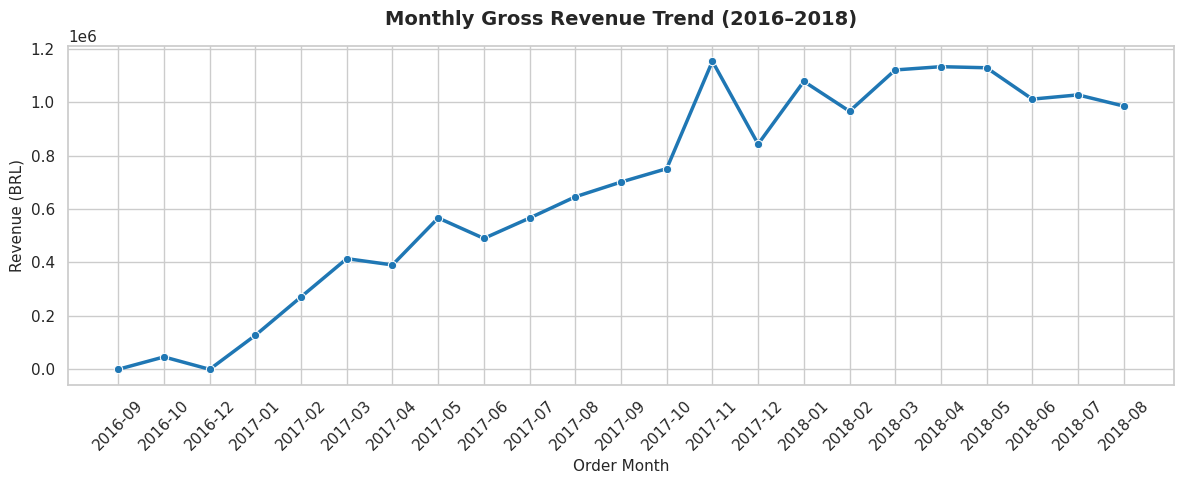

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean, modern visual style
sns.set_theme(style="whitegrid")

# Filter out the incomplete first/last partial months if needed, or plot all
plt.figure(figsize=(12, 5))
ax = sns.lineplot(
    data=monthly_sales,
    x='order_month',
    y='monthly_revenue',
    marker='o',
    linewidth=2.5,
    color='#1f77b4'
)

plt.title('Monthly Gross Revenue Trend (2016–2018)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Order Month', fontsize=11)
plt.ylabel('Revenue (BRL)', fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()

# Save high-res image for your GitHub README
plt.savefig('chart1_monthly_revenue.png', dpi=300)
plt.show()

/tmp/ipykernel_1029/2205798369.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1029/2205798369.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


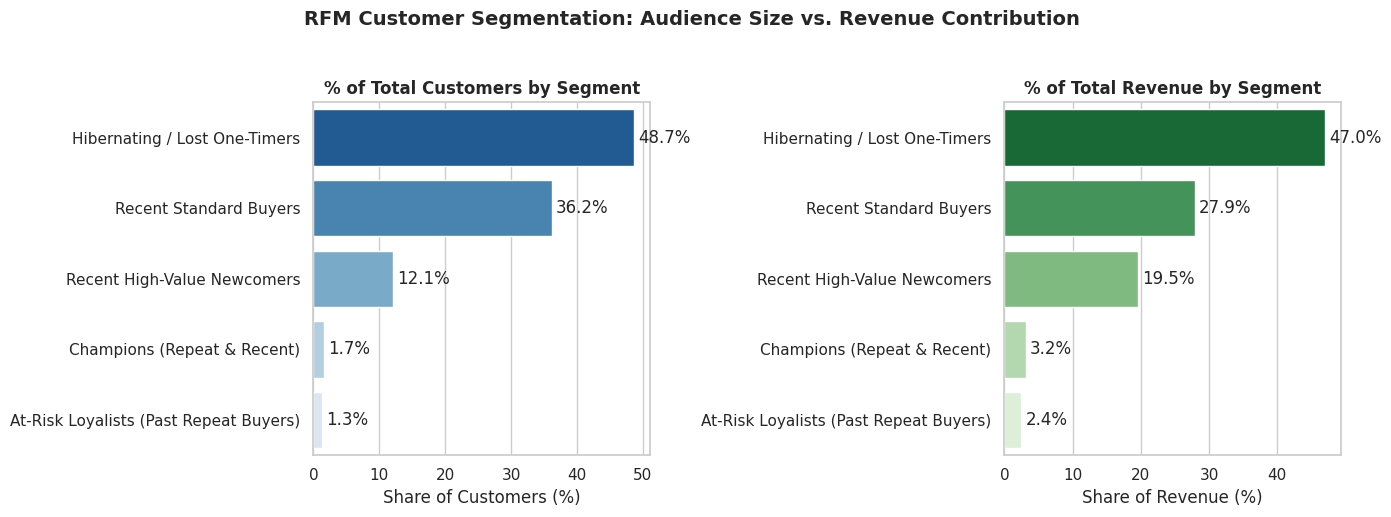

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left Plot: Percentage of Customers
sns.barplot(
    data=segment_summary,
    y='customer_segment',
    x='pct_customers',
    ax=axes[0],
    palette='Blues_r'
)
axes[0].set_title('% of Total Customers by Segment', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Share of Customers (%)')
axes[0].set_ylabel('')

# Add value labels on bars
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.1f%%', padding=3)

# Right Plot: Percentage of Total Revenue
sns.barplot(
    data=segment_summary,
    y='customer_segment',
    x='pct_revenue',
    ax=axes[1],
    palette='Greens_r'
)
axes[1].set_title('% of Total Revenue by Segment', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Share of Revenue (%)')
axes[1].set_ylabel('')

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.1f%%', padding=3)

plt.suptitle('RFM Customer Segmentation: Audience Size vs. Revenue Contribution', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('chart2_rfm_segments.png', dpi=300, bbox_inches='tight')
plt.show()

            delivery_status  total_customers  repeat_buyer_rate_pct
0             Late Delivery             7605                   2.52
1  On-Time / Early Delivery            85745                   3.04


/tmp/ipykernel_1029/2141061946.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


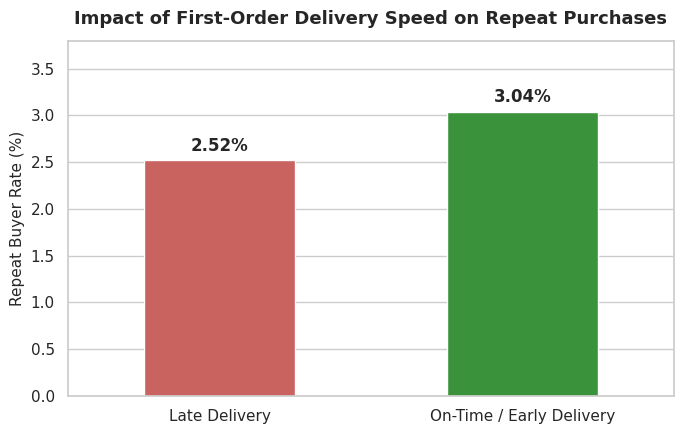

In [ ]:
# SQL query comparing repeat purchase rate for On-Time vs. Late first orders
delivery_impact = run_sql("""
WITH first_orders AS (
    SELECT
        customer_unique_id,
        MIN(order_purchase_timestamp) AS first_order_date,
        CASE
            WHEN JULIANDAY(order_delivered_customer_date) > JULIANDAY(order_estimated_delivery_date)
            THEN 'Late Delivery'
            ELSE 'On-Time / Early Delivery'
        END AS delivery_status
    FROM clean_orders
    GROUP BY customer_unique_id
),
repeat_flag AS (
    SELECT
        f.customer_unique_id,
        f.delivery_status,
        CASE WHEN r.frequency > 1 THEN 1 ELSE 0 END AS is_repeat_buyer
    FROM first_orders f
    JOIN customer_rfm r ON f.customer_unique_id = r.customer_unique_id
)
SELECT
    delivery_status,
    COUNT(*) AS total_customers,
    ROUND(100.0 * AVG(is_repeat_buyer), 2) AS repeat_buyer_rate_pct
FROM repeat_flag
GROUP BY delivery_status;
""")

print(delivery_impact)

# Plot Chart 3
plt.figure(figsize=(7, 4.5))
ax = sns.barplot(
    data=delivery_impact,
    x='delivery_status',
    y='repeat_buyer_rate_pct',
    palette=['#d9534f', '#2ca02c'],
    width=0.5
)
plt.title('Impact of First-Order Delivery Speed on Repeat Purchases', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('')
plt.ylabel('Repeat Buyer Rate (%)', fontsize=11)
plt.ylim(0, delivery_impact['repeat_buyer_rate_pct'].max() * 1.25)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=4, fontweight='bold')

plt.tight_layout()
plt.savefig('chart3_delivery_vs_retention.png', dpi=300)
plt.show()